# Evaluation

## 1. Setup

### 1.1. Imports, Drive y Rutas

In [ ]:
from pathlib import Path
from collections import Counter, defaultdict
import json, math, os, re, time
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = Path('/content/drive/MyDrive/NoteVision')
RAW_DIR = PROJECT_DIR / 'data_raw'
ARTIFACTS_DIR = PROJECT_DIR / 'artifacts'
LOCAL_DIR = Path('/content/primus')
ARCHIVE = RAW_DIR / 'primus.tgz'
EXPECTED_SAMPLES = 87_678
SEED = 42

def count_samples(root):
    n = 0
    for pkg in ('package_aa', 'package_ab'):
        p = root / pkg
        if p.exists():
            n += sum(1 for d in p.iterdir() if d.is_dir() and not d.name.startswith('._'))
    return n

if count_samples(LOCAL_DIR) != EXPECTED_SAMPLES:
    LOCAL_DIR.mkdir(parents=True, exist_ok=True)
    !tar -xzf $ARCHIVE -C $LOCAL_DIR

n = count_samples(LOCAL_DIR)
print('Samples on disk:', n)
assert n == EXPECTED_SAMPLES, 'Incomplete extraction'

gpus = tf.config.list_physical_devices('GPU')
print('GPUs:', gpus)  # inference works on CPU too, but use the T4 runtime for speed
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)
tf.keras.utils.set_random_seed(SEED)

Mounted at /content/drive
Samples on disk: 87678
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 1.2. Definition from 03-Modeling

In [ ]:
IMG_HEIGHT = 128
CTC_BLANK = 0  # class 0 = blank; token id i -> class i + 1
BOUNDS = list(range(600, 2201, 100)) + [2600, 3000, 3600]
MAX_PIXELS = 48000
MAX_BATCH = 64
BATCH_SIZES = [max(4, min(MAX_BATCH, MAX_PIXELS // b)) for b in BOUNDS] + [4]

def load_vocab(vocab_csv):
    df = pd.read_csv(vocab_csv, dtype=str, keep_default_na=False)
    tokens = df['token'].tolist()
    return tokens, {t: i for i, t in enumerate(tokens)}, len(tokens)

def encode_labels(df, token_to_id, max_len):
    labels = np.zeros((len(df), max_len), dtype=np.int32)
    lengths = np.zeros(len(df), dtype=np.int32)
    for i, seq in enumerate(df['label']):
        ids = [token_to_id[t] for t in seq.split()]
        labels[i, :len(ids)] = ids
        lengths[i] = len(ids)
    return labels, lengths

def decode_ids(ids, tokens):
    return ' '.join(tokens[i] for i in ids)

def image_path(root, package, sid):
    return Path(root) / package / sid / f'{sid}.png'

def load_image(path):
    raw = tf.io.read_file(path)
    img = tf.io.decode_png(raw, channels=3)  # palette (mode P) -> RGB
    gray = tf.image.rgb_to_grayscale(img)
    h = tf.cast(tf.shape(gray)[0], tf.float32)
    w = tf.cast(tf.shape(gray)[1], tf.float32)
    new_w = tf.maximum(1, tf.cast(tf.round(w * IMG_HEIGHT / h), tf.int32))
    gray = tf.image.resize(tf.cast(gray, tf.float32), (IMG_HEIGHT, new_w),
                           method='bilinear', antialias=True)
    gray = tf.clip_by_value(gray, 0.0, 255.0)
    return 1.0 - gray / 255.0, new_w  # ink = 1, background/padding = 0

# Horizontal reduction -> pooling layout (8: EXP-00 / EXP-02; 4: EXP-01)
POOLS = {8: ((2, 2), (2, 2), (2, 2), (2, 1)),
         4: ((2, 2), (2, 2), (2, 1), (2, 1))}

class CRNN(keras.Model):
    def __init__(self, num_classes, lstm_units=128, dropout=0.25, reduction=8, **kw):
        super().__init__(**kw)
        assert reduction in POOLS, f'unsupported reduction: {reduction}'
        self.reduction = reduction
        filters = (32, 64, 128, 256)
        self.convs = [layers.Conv2D(f, 3, padding='same', use_bias=False) for f in filters]
        self.bns = [layers.BatchNormalization() for _ in filters]
        self.pools = [layers.MaxPool2D(p) for p in POOLS[reduction]]
        self.proj = layers.Dense(256, activation='relu')
        self.drop = layers.Dropout(dropout)
        self.rnn1 = layers.Bidirectional(layers.LSTM(lstm_units, return_sequences=True))
        self.rnn2 = layers.Bidirectional(layers.LSTM(lstm_units, return_sequences=True))
        self.classifier = layers.Dense(num_classes)

    def call(self, inputs, training=False):
        x, widths = inputs['image'], inputs['width']
        for conv, bn, pool in zip(self.convs, self.bns, self.pools):
            x = pool(tf.nn.relu(bn(conv(x), training=training)))
        x = tf.transpose(x, [0, 2, 1, 3])
        s = tf.shape(x)
        x = tf.reshape(x, [s[0], s[1], x.shape[2] * x.shape[3]])
        x = self.drop(self.proj(x), training=training)
        logit_len = widths // self.reduction
        mask = tf.sequence_mask(logit_len, maxlen=s[1])
        x = self.rnn1(x, mask=mask, training=training)
        x = self.rnn2(self.drop(x, training=training), mask=mask, training=training)
        return self.classifier(self.drop(x, training=training)), logit_len

def greedy_decode(logits, lengths, blank=CTC_BLANK):
    ids = np.argmax(logits, axis=-1)
    out = []
    for seq, n in zip(ids, lengths):
        seq = seq[:n]
        changed = np.concatenate([[True], seq[1:] != seq[:-1]])
        seq = seq[changed]
        out.append((seq[seq != blank] - 1).tolist())
    return out

def make_infer(model):
    @tf.function(input_signature=[tf.TensorSpec([None, IMG_HEIGHT, None, 1], tf.float32),
                                  tf.TensorSpec([None], tf.int32)])
    def infer(image, width):
        return model({'image': image, 'width': width}, training=False)
    return infer

def build_eval_dataset(df, root, token_to_id, max_label_len):
    """Same bucketed pipeline as validation in 03, plus the row index to restore order."""
    labels, lengths = encode_labels(df, token_to_id, max_label_len)
    paths = [str(image_path(root, p, i)) for p, i in zip(df['package'], df['id'])]
    idx = np.arange(len(df), dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels, lengths, idx))

    def _map(path, label, length, i):
        image, width = load_image(path)
        return {'image': image, 'width': width, 'label': label,
                'label_length': length, 'idx': i}

    ds = ds.map(_map, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.bucket_by_sequence_length(
        element_length_func=lambda e: e['width'],
        bucket_boundaries=BOUNDS, bucket_batch_sizes=BATCH_SIZES,
        padded_shapes={'image': [IMG_HEIGHT, None, 1], 'width': [],
                       'label': [max_label_len], 'label_length': [], 'idx': []},
        padding_values={'image': tf.constant(0.0), 'width': tf.constant(0, tf.int32),
                        'label': tf.constant(0, tf.int32),
                        'label_length': tf.constant(0, tf.int32),
                        'idx': tf.constant(0, tf.int32)},
        pad_to_bucket_boundary=True, drop_remainder=False)
    return ds.prefetch(tf.data.AUTOTUNE)

def predict_indexed(infer, ds, n):
    hyps, widths = [None] * n, np.zeros(n, dtype=np.int32)
    for b in ds:
        logits, logit_len = infer(b['image'], b['width'])
        out = greedy_decode(logits.numpy(), logit_len.numpy())
        for i, h, w in zip(b['idx'].numpy(), out, b['width'].numpy()):
            hyps[i] = h
            widths[i] = w
    assert all(h is not None for h in hyps), 'some samples were not predicted'
    return hyps, widths

def align_pairs(ref, hyp):
    """Edit distance + ops (op, ref_token, hyp_token); same tie-breaking as the 03 align."""
    if ref == hyp:
        return 0, [('hit', t, t) for t in ref]
    n, m = len(ref), len(hyp)
    d = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(n + 1):
        d[i][0] = i
    for j in range(m + 1):
        d[0][j] = j
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            d[i][j] = min(d[i-1][j] + 1, d[i][j-1] + 1,
                          d[i-1][j-1] + (ref[i-1] != hyp[j-1]))
    ops, i, j = [], n, m
    while i > 0 or j > 0:
        if i > 0 and j > 0 and d[i][j] == d[i-1][j-1] + (ref[i-1] != hyp[j-1]):
            ops.append(('hit' if ref[i-1] == hyp[j-1] else 'sub', ref[i-1], hyp[j-1]))
            i, j = i - 1, j - 1
        elif i > 0 and d[i][j] == d[i-1][j] + 1:
            ops.append(('del', ref[i-1], None))
            i -= 1
        else:
            ops.append(('ins', None, hyp[j-1]))
            j -= 1
    ops.reverse()
    return d[n][m], ops

def align(ref, hyp):
    d, ops = align_pairs(ref, hyp)
    return d, [(op, r) for op, r, _ in ops]

def evaluate_sequences(refs, hyps, families):
    tot_ref = tot_err = tot_err_shape = exact = 0
    per_fam = defaultdict(Counter)
    for r, h in zip(refs, hyps):
        dist, ops = align(r, h)
        tot_err += dist
        tot_ref += len(r)
        exact += int(r == h)
        tot_err_shape += align([families[i] for i in r], [families[i] for i in h])[0]
        for op, tok in ops:
            if tok is not None:
                per_fam[families[tok]][op] += 1
    metrics = {'cer': tot_err / tot_ref, 'seq_acc': exact / len(refs),
               'cer_shape': tot_err_shape / tot_ref,
               'n_sequences': len(refs), 'n_tokens': tot_ref}
    rows = []
    for fam, c in per_fam.items():
        support = c['hit'] + c['sub'] + c['del']
        rows.append({'family': fam, 'support': support, 'recall': c['hit'] / support})
    fam_df = pd.DataFrame(rows).sort_values('support', ascending=False).reset_index(drop=True)
    return metrics, fam_df

# Sanity checks
_m, _ = evaluate_sequences([[0, 1, 2]], [[0, 0, 2]], ['a', 'a', 'b'])
assert abs(_m['cer'] - 1/3) < 1e-9 and _m['cer_shape'] == 0.0 and _m['seq_acc'] == 0.0
_d, _ops = align_pairs([0, 1, 2], [0, 2])
assert _d == 1 and _ops == [('hit', 0, 0), ('del', 1, None), ('hit', 2, 2)]
print('Definitions OK.')

Definitions OK.


### 1.3. Bootstrap

In [ ]:
val = pd.read_csv(ARTIFACTS_DIR / 'split_val.csv', dtype=str)
val['seq_len'] = val['seq_len'].astype(int)
tokens, token_to_id, _ = load_vocab(ARTIFACTS_DIR / 'vocab_agnostic.csv')
cfg = json.loads((ARTIFACTS_DIR / 'preprocessing_config.json').read_text())
summ = json.loads((ARTIFACTS_DIR / 'split_summary.json').read_text())
assert IMG_HEIGHT == cfg['img_height'] and len(tokens) == cfg['vocab_size']
assert len(val) == summ['n_val']
MAX_LABEL_LEN = cfg['max_label_len']
NUM_CLASSES = len(tokens) + 1

families = [t.split('-')[0] for t in tokens]   # symbol without position, e.g. 'note.quarter'
kinds = [f.split('.')[0] for f in families]    # coarse kind, e.g. 'note'

POS_RE = re.compile(r'^([LS])(-?\d+)$')
def token_step(tok):
    """Staff step: space below line 1 = 0; line k -> 2k-1; space k -> 2k. None if no position."""
    m = POS_RE.match(tok.partition('-')[2])
    if m is None:
        return None
    n = int(m.group(2))
    return 2 * n - 1 if m.group(1) == 'L' else 2 * n
steps = [token_step(t) for t in tokens]
print('Val:', len(val), '| tokens:', len(tokens), '| tokens with a parsed position:',
      sum(s is not None for s in steps))

Val: 8772 | tokens: 758 | tokens with a parsed position: 758


## 2. Load experiment

Set `EXP_ID` and the checkpoint folder of the run to evaluate. The model is rebuilt from the config stored in the run (`reduction` defaults to 8 for runs created before that key existed, such as EXP-00). Section 11 compares the run with EXP-00.

In [ ]:
EXP_ID = 'EXP-02'
RUN_DIR = ARTIFACTS_DIR / 'checkpoints' / 'exp02'
OUT_DIR = ARTIFACTS_DIR / f"eval_{EXP_ID.lower().replace('-', '')}_val"
OUT_DIR.mkdir(exist_ok=True)
BASELINE_CER = 0.91  # trivial predictors, approx. (STATUS.md)

def read_run_config(run_dir):
    ptr = json.loads((run_dir / 'latest.json').read_text())
    return json.loads((run_dir / ptr['slot'] / 'state.json').read_text())['config']

def load_experiment(run_dir):
    run_cfg = read_run_config(run_dir)
    model = CRNN(NUM_CLASSES, lstm_units=run_cfg['lstm_units'], dropout=run_cfg['dropout'],
                 reduction=run_cfg.get('reduction', 8))
    model({'image': tf.zeros([1, IMG_HEIGHT, 256, 1]), 'width': tf.constant([256])})  # build weights
    model.load_weights(run_dir / 'best.weights.h5')
    best = json.loads((run_dir / 'best.json').read_text())
    return model, make_infer(model), best, run_cfg

model, infer, best, run_cfg = load_experiment(RUN_DIR)
print(EXP_ID, '| best epoch', int(best['epoch']), '| params', f'{model.count_params():,}',
      '| subset CER in training log', round(best['val_cer'], 4))

EXP-02 | best epoch 8 | params 1,897,367 | subset CER in training log 0.0064


## 3. Inference on full validation set

In [ ]:
t0 = time.time()
ds_val = build_eval_dataset(val, LOCAL_DIR, token_to_id, MAX_LABEL_LEN)
hyps, widths = predict_indexed(infer, ds_val, len(val))
refs = [[token_to_id[t] for t in s.split()] for s in val['label']]
print(f'{len(val)} images in {time.time() - t0:.0f}s')

metrics, fam_df = evaluate_sequences(refs, hyps, families)
print(f"FULL VAL | CER {metrics['cer']:.4f} | seq_acc {metrics['seq_acc']:.4f} | "
      f"cer_shape {metrics['cer_shape']:.4f} | {metrics['n_sequences']} sequences, "
      f"{metrics['n_tokens']} tokens | trivial baseline CER ~ {BASELINE_CER}")

# Cross-check against the 2 000-sample subset used during training
sub_ids = pd.read_csv(ARTIFACTS_DIR / 'val_subset_ids.csv', dtype=str)
sub_keys = set(sub_ids['package'] + '/' + sub_ids['id'])
mask = (val['package'] + '/' + val['id']).isin(sub_keys).to_numpy()
m_sub, _ = evaluate_sequences([r for r, k in zip(refs, mask) if k],
                              [h for h, k in zip(hyps, mask) if k], families)
diff = abs(m_sub['cer'] - best['val_cer'])
print(f"Subset ({int(mask.sum())}) CER recomputed {m_sub['cer']:.4f} vs training log "
      f"{best['val_cer']:.4f} -> {'OK' if diff < 1e-3 else 'CHECK: differs by ' + str(round(diff, 5))}")

8772 images in 133s
FULL VAL | CER 0.0059 | seq_acc 0.8935 | cer_shape 0.0047 | 8772 sequences, 240867 tokens | trivial baseline CER ~ 0.91
Subset (2000) CER recomputed 0.0064 vs training log 0.0064 -> OK


## 4. Error analysis

In [ ]:
def analyze_errors(refs, hyps):
    rows = []
    fam_stats = defaultdict(Counter)  # family of the REF token -> hit / sub_position / sub_shape / del
    confusions = Counter()            # (ref_token, hyp_token) substitutions
    inserted = Counter()              # predicted tokens with no reference counterpart
    shifts = Counter()                # staff-step shift for same-symbol, different-position errors
    totals = Counter()
    for i, (r, h) in enumerate(zip(refs, hyps)):
        dist, ops = align_pairs(r, h)
        n_sub = n_del = n_ins = 0
        for op, rt, ht in ops:
            if op == 'hit':
                fam_stats[families[rt]]['hit'] += 1
            elif op == 'sub':
                n_sub += 1
                if families[rt] == families[ht]:
                    cat = 'sub_position'
                    if steps[rt] is not None and steps[ht] is not None:
                        shifts[steps[ht] - steps[rt]] += 1
                else:
                    cat = 'sub_shape'
                fam_stats[families[rt]][cat] += 1
                confusions[(rt, ht)] += 1
                totals[cat] += 1
            elif op == 'del':
                n_del += 1
                fam_stats[families[rt]]['del'] += 1
                totals['del'] += 1
            else:
                n_ins += 1
                inserted[ht] += 1
                totals['ins'] += 1
        rows.append((i, len(r), len(h), dist, n_sub, n_del, n_ins))
    per_sample = pd.DataFrame(rows, columns=['idx', 'ref_len', 'hyp_len', 'dist',
                                             'n_sub', 'n_del', 'n_ins'])
    return per_sample, fam_stats, confusions, inserted, shifts, totals

def family_table(stats, key_fn=lambda f: f):
    agg = defaultdict(Counter)
    for fam, c in stats.items():
        agg[key_fn(fam)].update(c)
    rows = []
    for k, c in agg.items():
        support = c['hit'] + c['sub_position'] + c['sub_shape'] + c['del']
        rows.append({'family': k, 'support': support,
                     'recall': c['hit'] / support,
                     'recall_shape': (c['hit'] + c['sub_position']) / support,
                     'pos_errors': c['sub_position'], 'shape_errors': c['sub_shape'],
                     'missed': c['del']})
    return pd.DataFrame(rows).sort_values('support', ascending=False).reset_index(drop=True)

per_sample, fam_stats, confusions, inserted, shifts, totals = analyze_errors(refs, hyps)
per_sample['width'] = widths

# Consistency with the official metric
n_tok = int(per_sample['ref_len'].sum())
total_err = sum(totals[k] for k in ('sub_position', 'sub_shape', 'del', 'ins'))
assert total_err == int(per_sample['dist'].sum())
assert abs(total_err / n_tok - metrics['cer']) < 1e-12, 'decomposition does not match CER'
fine = family_table(fam_stats)
chk = fam_df.merge(fine, on='family', suffixes=('_a', '_b'))
assert (chk['support_a'] == chk['support_b']).all() and np.allclose(chk['recall_a'], chk['recall_b'])
print('Decomposition consistent with evaluate_sequences.')

Decomposition consistent with evaluate_sequences.


## 5. Error decomposition

In [ ]:
pd.set_option('display.width', 200)
order = ['sub_position', 'sub_shape', 'del', 'ins']
labels_es = {'sub_position': 'same symbol, wrong position', 'sub_shape': 'wrong symbol',
             'del': 'missed (deletion)', 'ins': 'extra (insertion)'}
dec = pd.DataFrame({'type': [labels_es[k] for k in order],
                    'count': [totals[k] for k in order],
                    'rate_vs_ref_tokens': [totals[k] / n_tok for k in order],
                    'share_of_errors': [totals[k] / total_err for k in order]})
print(f"CER = {total_err / n_tok:.4f}  (= sum of the rates below)")
display(dec.round(4))

print('\nPosition shift in staff steps (hyp - ref) for "same symbol, wrong position":')
sh = pd.DataFrame(sorted(shifts.items()), columns=['shift', 'count'])
sh['share'] = sh['count'] / sh['count'].sum()
display(sh.round(3))

print('\nTop 20 substitutions (ref -> hyp):')
conf = pd.DataFrame([{'ref': tokens[r], 'hyp': tokens[h], 'count': c,
                      'type': 'position' if families[r] == families[h] else 'symbol'}
                     for (r, h), c in confusions.most_common(20)])
display(conf)

print('\nMost missed families / most inserted tokens:')
missed = sorted(((f, c['del']) for f, c in fam_stats.items() if c['del']), key=lambda x: -x[1])[:10]
display(pd.DataFrame(missed, columns=['family (missed)', 'count']))
display(pd.DataFrame([(tokens[t], c) for t, c in inserted.most_common(10)],
                     columns=['token (inserted)', 'count']))

CER = 0.0059  (= sum of the rates below)


,type,count,rate_vs_ref_tokens,share_of_errors
0,"same symbol, wrong position",257,0.0011,0.1821
1,wrong symbol,145,0.0006,0.1028
2,missed (deletion),503,0.0021,0.3565
3,extra (insertion),506,0.0021,0.3586



Position shift in staff steps (hyp - ref) for "same symbol, wrong position":


,shift,count,share
0,-5,2,0.008
1,-4,1,0.004
2,-3,1,0.004
3,-2,33,0.128
4,-1,76,0.296
5,1,92,0.358
6,2,45,0.175
7,3,1,0.004
8,4,4,0.016
9,5,1,0.004



Top 20 substitutions (ref -> hyp):


,ref,hyp,count,type
0,gracenote.sixteenth-L4,gracenote.sixteenth-S3,14,position
1,gracenote.sixteenth-L4,gracenote.sixteenth-S4,13,position
2,gracenote.sixteenth-S3,gracenote.sixteenth-L4,11,position
3,gracenote.sixteenth-L6,gracenote.sixteenth-S5,8,position
4,gracenote.sixteenth-L3,gracenote.sixteenth-S3,8,position
5,gracenote.sixteenth-S3,gracenote.sixteenth-L3,7,position
6,gracenote.sixteenth-L5,gracenote.sixteenth-S4,7,position
7,gracenote.sixteenth-L2,gracenote.sixteenth-S2,6,position
8,gracenote.sixteenth-S5,gracenote.sixteenth-L6,5,position
9,gracenote.sixteenth-L3,gracenote.sixteenth-S2,5,position



Most missed families / most inserted tokens:


,family (missed),count
0,accidental.natural,210
1,barline,105
2,accidental.flat,86
3,slur.end,26
4,slur.start,22
5,accidental.sharp,19
6,gracenote.sixteenth,9
7,gracenote.beamedBoth2,4
8,gracenote.thirty_second,3
9,dot,2


,token (inserted),count
0,barline-L1,244
1,slur.start-L3,12
2,slur.start-L5,12
3,slur.start-S5,12
4,slur.end-L4,12
5,slur.end-L3,12
6,slur.end-L5,11
7,accidental.flat-L4,11
8,slur.start-S4,11
9,slur.start-L6,10


## 6. Recall by symbol family

In [ ]:
MIN_SUPPORT = 100
coarse = family_table(fam_stats, key_fn=lambda f: f.split('.')[0])
print('By coarse kind (recall = exact token; recall_shape ignores position):')
display(coarse.round(4))

print('\nTop 25 families by support:')
display(fine.head(25).round(4))

print(f'\nWorst 15 families by recall (support >= {MIN_SUPPORT}):')
display(fine[fine['support'] >= MIN_SUPPORT].sort_values('recall').head(15).round(4))

By coarse kind (recall = exact token; recall_shape ignores position):


,family,support,recall,recall_shape,pos_errors,shape_errors,missed
0,note,133595,0.9992,0.9994,24,74,9
1,barline,32594,0.9967,0.9967,0,3,105
2,accidental,17331,0.9793,0.9800,13,31,315
3,rest,13114,0.9999,0.9999,0,0,1
4,dot,11826,0.9994,0.9995,1,4,2
5,digit,11175,0.9995,0.9995,0,5,1
6,clef,8849,0.9992,0.9992,0,4,3
7,metersign,4796,1.0000,1.0000,0,0,0
8,slur,2594,0.9788,0.9788,0,7,48
9,multirest,2294,0.9996,0.9996,0,1,0



Top 25 families by support:


,family,support,recall,recall_shape,pos_errors,shape_errors,missed
0,note.quarter,34243,0.9997,0.9998,4,5,1
1,barline,32594,0.9967,0.9967,0,3,105
2,note.eighth,22655,0.9998,1.0000,4,0,0
3,note.beamedRight1,13475,0.9996,0.9997,2,3,1
4,dot,11826,0.9994,0.9995,1,4,2
5,note.half,11387,0.9998,1.0000,2,0,0
6,note.beamedLeft1,10168,0.9998,1.0000,2,0,0
7,note.beamedBoth2,9003,1.0000,1.0000,0,0,0
8,note.beamedLeft2,8806,0.9997,0.9997,0,3,0
9,accidental.sharp,8457,0.9956,0.9966,8,10,19



Worst 15 families by recall (support >= 100):


,family,support,recall,recall_shape,pos_errors,shape_errors,missed
35,gracenote.sixteenth,700,0.7557,0.9829,159,3,9
26,accidental.natural,1489,0.8469,0.8475,1,17,210
29,slur.end,1297,0.9776,0.9776,0,3,26
28,slur.start,1297,0.9800,0.9800,0,4,22
11,accidental.flat,7385,0.9873,0.9878,4,4,86
46,digit.9,144,0.9931,0.9931,0,1,0
45,note.thirty_second,164,0.9939,1.0000,1,0,0
32,gracenote.eighth,1190,0.9941,0.9975,4,1,2
44,gracenote.quarter,172,0.9942,0.9942,0,1,0
40,note.double_whole,356,0.9944,0.9944,0,0,2


## 7. Errors by sequence length and image width

In [ ]:
def cer_by(col, bins):
    g = per_sample.assign(bin=bins).groupby('bin', observed=True).agg(
        n=('idx', 'size'), dist=('dist', 'sum'), ref=('ref_len', 'sum'),
        seq_acc=('dist', lambda s: (s == 0).mean()))
    g['cer'] = g['dist'] / g['ref']
    return g[['n', 'ref', 'dist', 'cer', 'seq_acc']].round(4)

print('By reference length (tokens):')
display(cer_by('ref_len', pd.cut(per_sample['ref_len'], [0, 20, 40, 60, MAX_LABEL_LEN])))
print('\nBy image width after resize (quintiles):')
display(cer_by('width', pd.qcut(per_sample['width'], 5, duplicates='drop')))

By reference length (tokens):


,n,ref,dist,cer,seq_acc
bin,,,,,
"(0, 20]",1296,22610,179,0.0079,0.9028
"(20, 40]",7145,203623,1091,0.0054,0.8984
"(40, 60]",329,14511,139,0.0096,0.7538
"(60, 75]",2,123,2,0.0163,0.5000



By image width after resize (quintiles):


,n,ref,dist,cer,seq_acc
bin,,,,,
"(360.999, 918.0]",1764,41206,265,0.0064,0.8991
"(918.0, 1072.0]",1752,46314,246,0.0053,0.9047
"(1072.0, 1219.0]",1750,49314,239,0.0048,0.9137
"(1219.0, 1433.0]",1753,51073,288,0.0056,0.8956
"(1433.0, 3417.0]",1753,52960,373,0.0070,0.8545


## 8. REF/HYP examples

=== 6 worst samples ===
idx 643 | package_aa/000105627-1_1_1 | 18 ref tokens | 9 edit(s)
  before ref[10] (extra) note.quarter-L4
  ref[10] note.beamedRight0-L4  ->  note.quarter-L5
  ref[11] note.beamedBoth0-L5  ->  note.quarter-S4
  ref[12] note.beamedBoth0-S4  ->  note.quarter-L4
  ref[13] note.beamedLeft0-L4  ->  note.quarter-L4
  ref[14] note.beamedRight0-L4  ->  note.quarter-L3
  ref[15] note.beamedLeft0-L3  ->  note.quarter-S3
  ref[16] note.beamedRight0-S3  ->  note.quarter-S4
  ref[17] note.beamedLeft0-S4  ->  barline-L1
REF: clef.G-L2 metersign.C-L3 note.quarter-S2 barline-L1 note.quarter-S4 note.quarter-S3 note.quarter-L3 rest.quarter-L3 note.quarter-L3 barline-L1 note.beamedRight0-L4 note.beamedBoth0-L5 note.beamedBoth0-S4 note.beamedLeft0-L4 note.beamedRight0-L4 note.beamedLeft0-L3 note.beamedRight0-S3 note.beamedLeft0-S4
HYP: clef.G-L2 metersign.C-L3 note.quarter-S2 barline-L1 note.quarter-S4 note.quarter-S3 note.quarter-L3 rest.quarter-L3 note.quarter-L3 barline-L1 note.

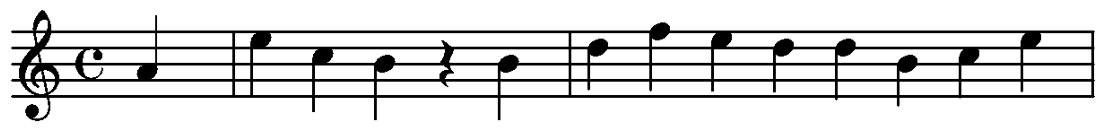

idx 6530 | package_ab/211007103-1_8_1 | 37 ref tokens | 8 edit(s)
  ref[8] note.beamedBoth4-S-1  ->  note.beamedBoth3-S-1
  ref[10] note.beamedLeft4-L0  ->  note.beamedLeft3-L0
  ref[14] accidental.flat-S-1  ->  (missing)
  ref[15] note.beamedBoth4-S-1  ->  (missing)
  ref[16] accidental.natural-L0  ->  note.beamedBoth3-S-1
  ref[17] note.beamedLeft4-L0  ->  note.beamedLeft3-L0
  ref[21] note.beamedBoth4-S-1  ->  note.beamedBoth3-S-1
  ref[22] note.beamedLeft4-L0  ->  note.beamedLeft3-L0
REF: clef.G-L2 accidental.flat-L3 digit.3-L4 digit.4-L2 note.beamedRight1-S0 rest.sixteenth-L3 note.beamedBoth3-L-1 accidental.natural-S-1 note.beamedBoth4-S-1 accidental.sharp-L0 note.beamedLeft4-L0 note.beamedRight1-S0 rest.sixteenth-L3 note.beamedBoth3-L-1 accidental.flat-S-1 note.beamedBoth4-S-1 accidental.natural-L0 note.beamedLeft4-L0 note.beamedRight1-S0 rest.sixteenth-L3 note.beamedBoth3-L-1 note.beamedBoth4-S-1 note.beamedLeft4-L0 barline-L1 note.sixteenth-S0 note.beamedRight2-S2 note.beamedBo

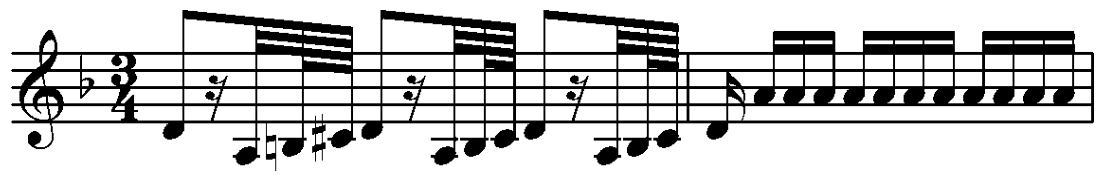

idx 6595 | package_ab/211008117-1_2_1 | 28 ref tokens | 7 edit(s)
  ref[7] slur.start-S3  ->  slur.end-L3
  before ref[9] (extra) slur.start-L3
  before ref[10] (extra) slur.end-L3
  ref[14] slur.end-S3  ->  (missing)
  ref[16] slur.start-S3  ->  (missing)
  ref[25] slur.end-S3  ->  note.whole-S3
  ref[26] note.whole-S3  ->  slur.end-L4
REF: clef.C-L1 metersign.C/-L3 note.whole-S3 slur.start-S3 note.whole-L3 slur.end-S3 note.whole-S3 slur.start-S3 note.whole-L3 note.whole-S2 note.whole-L3 note.whole-L3 note.whole-L4 note.whole-S4 slur.end-S3 note.whole-S3 slur.start-S3 slur.end-S3 note.whole-S3 slur.start-S3 note.whole-L3 slur.end-S3 note.whole-S3 slur.start-S3 note.whole-L4 slur.end-S3 note.whole-S3 note.whole-L4
HYP: clef.C-L1 metersign.C/-L3 note.whole-S3 slur.start-S3 note.whole-L3 slur.end-S3 note.whole-S3 slur.end-L3 note.whole-L3 slur.start-L3 note.whole-S2 slur.end-L3 note.whole-L3 note.whole-L3 note.whole-L4 note.whole-S4 note.whole-S3 slur.end-S3 note.whole-S3 slur.start-S3 n

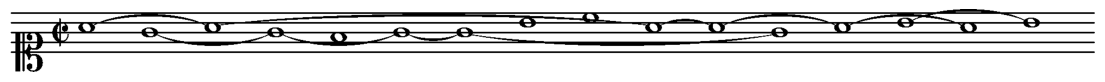

idx 785 | package_aa/000106909-1_2_1 | 20 ref tokens | 7 edit(s)
  ref[11] note.beamedRight0-S5  ->  note.quarter-S5
  ref[12] note.beamedBoth0-S3  ->  note.quarter-S3
  ref[13] note.beamedLeft0-L4  ->  note.quarter-L4
  ref[14] note.beamedRight0-S4  ->  note.quarter-S4
  ref[15] note.beamedBoth0-S5  ->  note.quarter-S5
  ref[16] note.beamedBoth0-S3  ->  note.quarter-S3
  ref[17] note.beamedLeft0-L4  ->  note.quarter-L4
REF: clef.F-L4 accidental.sharp-L4 metersign.C-L3 rest.eighth-L3 note.eighth-S5 note.quarter-S5 rest.eighth-L3 note.eighth-S5 note.quarter-S5 barline-L1 rest.quarter-L3 note.beamedRight0-S5 note.beamedBoth0-S3 note.beamedLeft0-L4 note.beamedRight0-S4 note.beamedBoth0-S5 note.beamedBoth0-S3 note.beamedLeft0-L4 barline-L1 note.quarter-S4
HYP: clef.F-L4 accidental.sharp-L4 metersign.C-L3 rest.eighth-L3 note.eighth-S5 note.quarter-S5 rest.eighth-L3 note.eighth-S5 note.quarter-S5 barline-L1 rest.quarter-L3 note.quarter-S5 note.quarter-S3 note.quarter-L4 note.quarter-S4 note.

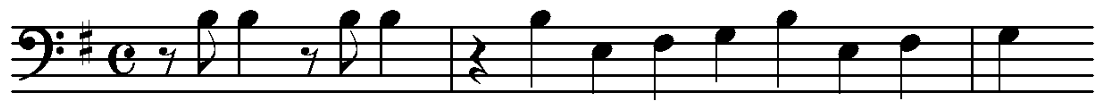

idx 3314 | package_aa/000131651-1_1_1 | 46 ref tokens | 6 edit(s)
  ref[4] gracenote.sixteenth-L3  ->  gracenote.sixteenth-S0
  ref[5] gracenote.sixteenth-S0  ->  gracenote.sixteenth-S2
  ref[28] note.beamedRight4-S5  ->  note.beamedRight3-S5
  ref[29] note.beamedBoth4-L6  ->  note.beamedBoth3-L6
  ref[34] note.beamedRight4-S5  ->  note.beamedRight3-S5
  ref[35] note.beamedBoth4-L6  ->  note.beamedBoth3-L6
REF: clef.G-L2 accidental.flat-L3 accidental.flat-S4 metersign.C-L3 gracenote.sixteenth-L3 gracenote.sixteenth-S0 note.beamedRight1-L5 dot-S5 note.beamedLeft2-S6 note.eighth-L4 rest.eighth-L3 dot-S3 note.beamedRight2-L4 note.beamedBoth2-S3 note.beamedLeft2-L4 note.beamedRight2-S4 note.beamedBoth2-S3 note.beamedBoth2-S5 dot-S5 note.beamedLeft3-L3 barline-L1 gracenote.eighth-L3 note.beamedRight1-S2 dot-S2 note.beamedBoth3-L3 note.beamedLeft3-S3 note.eighth-L3 rest.eighth-L3 note.beamedRight4-S5 note.beamedBoth4-L6 note.beamedLeft2-S6 dot-S6 note.beamedRight2-S5 note.beamedLeft2-S4 note

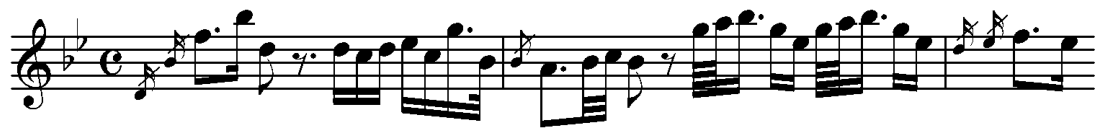

idx 2022 | package_aa/000117606-1_1_1 | 37 ref tokens | 6 edit(s)
  ref[4] accidental.flat-L3  ->  (missing)
  ref[6] gracenote.sixteenth-S3  ->  gracenote.sixteenth-L3
  ref[9] accidental.natural-L3  ->  (missing)
  ref[18] gracenote.sixteenth-L6  ->  gracenote.sixteenth-S5
  ref[19] gracenote.sixteenth-S5  ->  gracenote.sixteenth-L6
  ref[32] gracenote.sixteenth-L5  ->  gracenote.sixteenth-S4
REF: clef.G-L2 metersign.C-L3 note.quarter-S1 dot-S1 accidental.flat-L3 gracenote.sixteenth-L3 gracenote.sixteenth-S3 note.beamedRight2-L4 dot-S4 accidental.natural-L3 note.beamedLeft3-L3 note.eighth-S2 gracenote.sixteenth-L4 gracenote.sixteenth-S4 note.beamedRight2-L5 dot-S5 note.beamedLeft3-L4 note.eighth-S3 gracenote.sixteenth-L6 gracenote.sixteenth-S5 note.beamedRight2-S6 dot-S6 note.beamedLeft3-S6 barline-L1 note.eighth-L6 gracenote.sixteenth-L5 gracenote.sixteenth-S5 note.beamedRight2-L6 dot-S6 note.beamedLeft3-L6 note.eighth-S5 gracenote.sixteenth-S4 gracenote.sixteenth-L5 note.beamedRigh

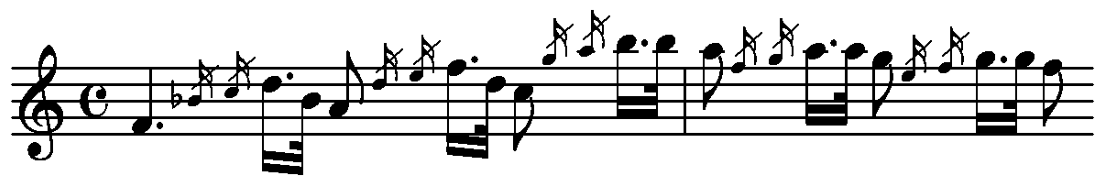


=== 6 random samples with 1-2 edits (typical errors) ===
idx 6327 | package_ab/211004545-1_13_1 | 50 ref tokens | 1 edit(s)
  ref[45] accidental.sharp-S3  ->  (missing)


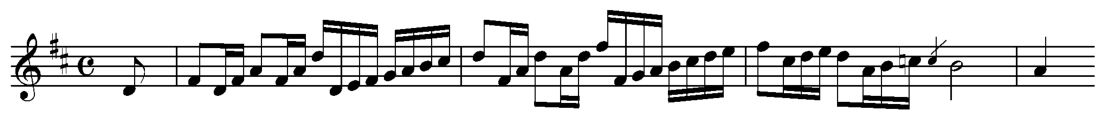

idx 4742 | package_ab/190003500-1_1_1 | 41 ref tokens | 2 edit(s)
  ref[37] accidental.natural-S2  ->  note.beamedBoth1-S2
  ref[38] note.beamedBoth1-S2  ->  accidental.natural-S2


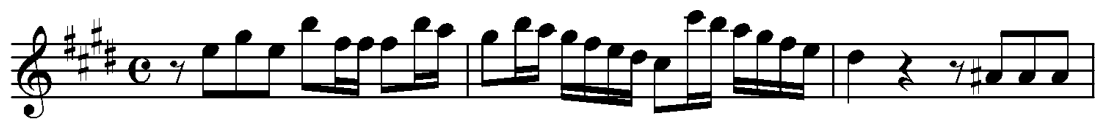

idx 2862 | package_aa/000125212-1_1_1 | 33 ref tokens | 1 edit(s)
  before ref[22] (extra) accidental.flat-S3


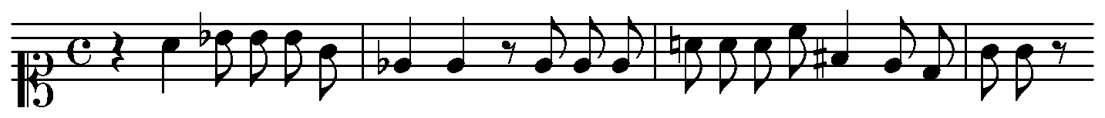

idx 5917 | package_ab/201009283-1_2_1 | 18 ref tokens | 1 edit(s)
  before ref[9] (extra) slur.end-S4


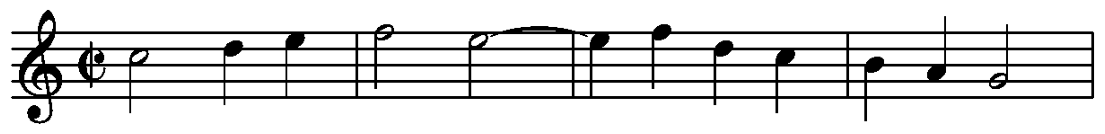

idx 1605 | package_aa/000113828-1_1_1 | 37 ref tokens | 1 edit(s)
  ref[36] barline-L1  ->  (missing)


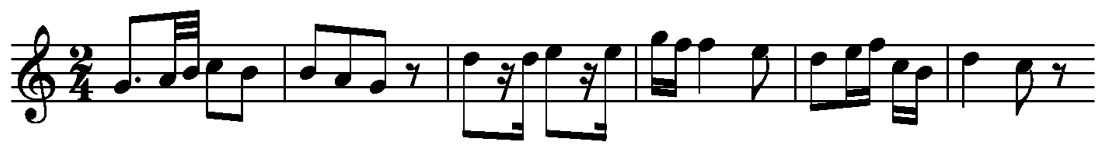

idx 6869 | package_ab/212001622-1_4_1 | 39 ref tokens | 1 edit(s)
  ref[31] accidental.natural-S1  ->  (missing)


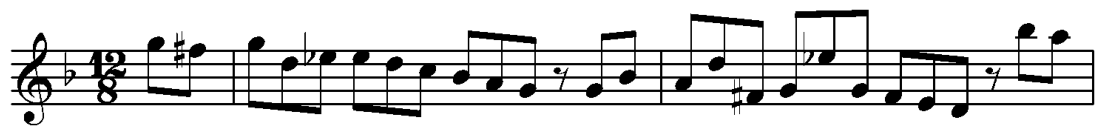

In [ ]:
def edit_script(ref, hyp):
    dist, ops = align_pairs(ref, hyp)
    out, k = [], 0
    for op, rt, ht in ops:
        if op == 'hit':
            k += 1
        elif op == 'sub':
            out.append(f'  ref[{k}] {tokens[rt]}  ->  {tokens[ht]}')
            k += 1
        elif op == 'del':
            out.append(f'  ref[{k}] {tokens[rt]}  ->  (missing)')
            k += 1
        else:
            out.append(f'  before ref[{k}] (extra) {tokens[ht]}')
    return out

def show_example(i, full=False):
    row = val.iloc[i]
    print(f"idx {i} | {row['package']}/{row['id']} | {len(refs[i])} ref tokens | "
          f"{int(per_sample.loc[i, 'dist'])} edit(s)")
    print('\n'.join(edit_script(refs[i], hyps[i])))
    if full:
        print('REF:', decode_ids(refs[i], tokens))
        print('HYP:', decode_ids(hyps[i], tokens))
    img = Image.open(image_path(LOCAL_DIR, row['package'], row['id'])).convert('L')
    plt.figure(figsize=(14, 3)); plt.imshow(img, cmap='gray'); plt.axis('off'); plt.show()

print('=== 6 worst samples ===')
for i in per_sample.sort_values('dist', ascending=False).head(6)['idx']:
    show_example(int(i), full=True)

print('\n=== 6 random samples with 1-2 edits (typical errors) ===')
small = per_sample[per_sample['dist'].between(1, 2)]
for i in small.sample(min(6, len(small)), random_state=SEED)['idx']:
    show_example(int(i))

## 9. Save results

In [ ]:
def to_py(x):
    return float(x) if isinstance(x, (np.floating, float)) else int(x)

summary = {
    'exp_id': EXP_ID, 'split': 'val_full', 'best_epoch': int(best['epoch']),
    'metrics': {k: to_py(v) for k, v in metrics.items()},
    'subset_check': {'cer_recomputed': float(m_sub['cer']), 'cer_training_log': float(best['val_cer'])},
    'error_rates': {k: totals[k] / n_tok for k in order},
    'error_counts': {k: int(totals[k]) for k in order},
}
(OUT_DIR / 'metrics_val.json').write_text(json.dumps(summary, indent=1))
fine.to_csv(OUT_DIR / 'recall_by_family.csv', index=False)
coarse.to_csv(OUT_DIR / 'recall_by_kind.csv', index=False)
errs = per_sample[per_sample['dist'] > 0].copy()
errs['package'] = val['package'].to_numpy()[errs['idx']]
errs['id'] = val['id'].to_numpy()[errs['idx']]
errs['ref'] = [decode_ids(refs[i], tokens) for i in errs['idx']]
errs['hyp'] = [decode_ids(hyps[i], tokens) for i in errs['idx']]
errs.to_csv(OUT_DIR / 'errors_val.csv', index=False)
print('Saved to', OUT_DIR)
print(f"{EXP_ID} full val | CER {metrics['cer']:.4f} | seq_acc {metrics['seq_acc']:.4f} | "
      f"cer_shape {metrics['cer_shape']:.4f}")

Saved to /content/drive/MyDrive/NoteVision/artifacts/eval_exp02_val
EXP-02 full val | CER 0.0059 | seq_acc 0.8935 | cer_shape 0.0047


## 10. Train-vs-val gap

### 10.1. Train subset in eval mode

In [ ]:
train = pd.read_csv(ARTIFACTS_DIR / 'split_train.csv', dtype=str)
tr_sub = train.sample(2000, random_state=SEED).reset_index(drop=True)
ds_tr = build_eval_dataset(tr_sub, LOCAL_DIR, token_to_id, MAX_LABEL_LEN)
h_tr, _ = predict_indexed(infer, ds_tr, len(tr_sub))
r_tr = [[token_to_id[t] for t in s.split()] for s in tr_sub['label']]
m_tr, _ = evaluate_sequences(r_tr, h_tr, families)

# Full-val numbers come from the file saved by section 9 (section 3 was not re-run)
mv = json.loads((OUT_DIR / 'metrics_val.json').read_text())['metrics']
print(f"TRAIN subset (2000) | CER {m_tr['cer']:.4f} | seq_acc {m_tr['seq_acc']:.4f} | "
      f"cer_shape {m_tr['cer_shape']:.4f}")
print(f"VAL full            | CER {mv['cer']:.4f} | seq_acc {mv['seq_acc']:.4f} | "
      f"cer_shape {mv['cer_shape']:.4f}")

TRAIN subset (2000) | CER 0.0046 | seq_acc 0.9145 | cer_shape 0.0035
VAL full            | CER 0.0059 | seq_acc 0.8935 | cer_shape 0.0047


### 10.2. Extra final barline inconsistency

In [ ]:
errs = pd.read_csv(OUT_DIR / 'errors_val.csv', dtype={'package': str, 'id': str})
r_last = errs['ref'].str.split().str[-1]
h_last = errs['hyp'].str.split().str[-1]
print('Error samples where HYP ends with an extra barline-L1:',
      int(((h_last == 'barline-L1') & (r_last != 'barline-L1')).sum()))
print('Error samples where REF ends with barline-L1 and HYP does not:',
      int(((r_last == 'barline-L1') & (h_last != 'barline-L1')).sum()))
ends = val['label'].str.split().str[-1]
print(f"Val references ending with barline-L1: {(ends == 'barline-L1').mean():.3f}")

Error samples where HYP ends with an extra barline-L1: 247
Error samples where REF ends with barline-L1 and HYP does not: 101
Val references ending with barline-L1: 0.523


## 11. Comparison with EXP-00 (effect of the oversampling)

Both runs are rebuilt from the files saved by section 9 (`metrics_val.json` and `errors_val.csv`; samples without errors have HYP = REF), so this section does not need sections 3-8 to be re-run, as long as section 9 was run for both experiments. Same validation set and same metrics for both. The success criteria are the ones pre-registered in `03_02_modeling.ipynb`.

### 11.1. Load both runs

In [ ]:
REF_ID = 'EXP-00'
REF_OUT_DIR = ARTIFACTS_DIR / f"eval_{REF_ID.lower().replace('-', '')}_val"
TARGET_FAMILIES = read_run_config(RUN_DIR)['target_families']   # families oversampled in this run
ERR_KINDS = ['sub_position', 'sub_shape', 'del', 'ins']
val_refs = [[token_to_id[t] for t in s.split()] for s in val['label']]

def load_run(out_dir):
    """Rebuild every hypothesis from errors_val.csv (error-free samples have HYP == REF) and re-run the error analysis."""
    meta = json.loads((out_dir / 'metrics_val.json').read_text())
    errs_df = pd.read_csv(out_dir / 'errors_val.csv', dtype={'package': str, 'id': str})
    hyps_x = [list(r) for r in val_refs]
    for i, ref_s, hyp_s in zip(errs_df['idx'], errs_df['ref'], errs_df['hyp']):
        assert decode_ids(val_refs[int(i)], tokens) == ref_s, f'idx {i}: reference does not match split_val'
        hyps_x[int(i)] = [token_to_id[t] for t in hyp_s.split()] if isinstance(hyp_s, str) else []
    per_s, fam_s, _, ins_s, _, tot_s = analyze_errors(val_refs, hyps_x)
    n_tok_x = int(per_s['ref_len'].sum())
    cer_x = sum(tot_s[k] for k in ERR_KINDS) / n_tok_x
    assert abs(cer_x - meta['metrics']['cer']) < 1e-9, f'{out_dir.name}: rebuilt CER {cer_x:.6f} != saved'
    ins_fam = Counter()
    for t, c in ins_s.items():
        ins_fam[families[t]] += c
    return {'meta': meta, 'refs': val_refs, 'hyps': hyps_x, 'per_sample': per_s, 'fam_stats': fam_s,
            'ins_fam': ins_fam, 'totals': tot_s, 'n_tok': n_tok_x}

run_ref, run_new = load_run(REF_OUT_DIR), load_run(OUT_DIR)
print(f"{REF_ID}: CER {run_ref['meta']['metrics']['cer']:.4f} | {EXP_ID}: CER {run_new['meta']['metrics']['cer']:.4f} "
      f"(rebuilt from the saved files and checked against metrics_val.json)")
print('Oversampled families in this run:', TARGET_FAMILIES)

EXP-00: CER 0.0067 | EXP-02: CER 0.0059 (rebuilt from the saved files and checked against metrics_val.json)
Oversampled families in this run: ['accidental.natural', 'slur.start', 'slur.end', 'gracenote.sixteenth', 'gracenote.thirty_second']


### 11.2. Global metrics

`rel_change` is relative to EXP-00 (negative = better for error metrics). `CER ignoring final barline-L1` removes a trailing `barline-L1` from both REF and HYP, which neutralizes the final-barline label inconsistency found in EXP-00 (section 10.2).

In [ ]:
BAR = token_to_id['barline-L1']

def drop_final_barline(seq):
    return seq[:-1] if seq and seq[-1] == BAR else seq

def cer_without_final_barline(run):
    err = sum(align_pairs(drop_final_barline(r), drop_final_barline(h))[0]
              for r, h in zip(run['refs'], run['hyps']))
    return err / sum(len(drop_final_barline(r)) for r in run['refs'])

def global_table(runs):
    rows = [(label, *[r['meta']['metrics'][key] for r in runs])
            for key, label in [('cer', 'CER'), ('cer_shape', 'cer_shape'), ('seq_acc', 'seq_acc')]]
    rows.append(('CER ignoring final barline-L1', *[cer_without_final_barline(r) for r in runs]))
    for k in ERR_KINDS:
        rows.append((f'rate: {k}', *[r['totals'][k] / r['n_tok'] for r in runs]))
    df_g = pd.DataFrame(rows, columns=['metric', REF_ID, EXP_ID])
    df_g['rel_change'] = df_g[EXP_ID] / df_g[REF_ID] - 1
    return df_g

glob_df = global_table([run_ref, run_new])
display(glob_df.round(4))

,metric,EXP-00,EXP-02,rel_change
0,CER,0.0067,0.0059,-0.1203
1,cer_shape,0.0054,0.0047,-0.1281
2,seq_acc,0.8805,0.8935,0.0148
3,CER ignoring final barline-L1,0.0054,0.0045,-0.1663
4,rate: sub_position,0.0011,0.0011,-0.0338
5,rate: sub_shape,0.0006,0.0006,0.0000
6,rate: del,0.0029,0.0021,-0.2814
7,rate: ins,0.0020,0.0021,0.0264


### 11.3. Oversampled families and control families

Recall is exact-token recall (symbol and position). `inserted` counts extra tokens of that family in the HYP; `net_errors` = substitutions + deletions (by REF family) + insertions (by HYP family). The control families were **not** oversampled: they show whether the rest of the model moved. `barline` is dominated by the final-barline inconsistency.

In [ ]:
def fam_row(run, fam):
    c = run['fam_stats'][fam]
    support = c['hit'] + c['sub_position'] + c['sub_shape'] + c['del']
    ins = run['ins_fam'][fam]
    return {'support': support, 'recall': c['hit'] / support if support else float('nan'),
            'missed': c['del'], 'inserted': ins,
            'net_errors': c['sub_position'] + c['sub_shape'] + c['del'] + ins}

CONTROL_FAMILIES = ['accidental.flat', 'accidental.sharp', 'barline']   # not oversampled
rows = []
for fam in TARGET_FAMILIES + CONTROL_FAMILIES:
    a, b = fam_row(run_ref, fam), fam_row(run_new, fam)
    rows.append({'family': fam, 'oversampled': fam in TARGET_FAMILIES, 'support': a['support'],
                 f'recall_{REF_ID}': a['recall'], f'recall_{EXP_ID}': b['recall'],
                 'recall_delta': b['recall'] - a['recall'],
                 f'missed_{REF_ID}': a['missed'], f'missed_{EXP_ID}': b['missed'],
                 f'inserted_{REF_ID}': a['inserted'], f'inserted_{EXP_ID}': b['inserted'],
                 f'net_errors_{REF_ID}': a['net_errors'], f'net_errors_{EXP_ID}': b['net_errors']})
fam_cmp = pd.DataFrame(rows)
display(fam_cmp.round(4))

tgt_ref = int(fam_cmp.loc[fam_cmp['oversampled'], f'net_errors_{REF_ID}'].sum())
tgt_new = int(fam_cmp.loc[fam_cmp['oversampled'], f'net_errors_{EXP_ID}'].sum())
print(f'Net errors in the oversampled families: {REF_ID} {tgt_ref} -> {EXP_ID} {tgt_new} ({tgt_new / tgt_ref - 1:+.1%})')

,family,oversampled,support,recall_EXP-00,recall_EXP-02,recall_delta,missed_EXP-00,missed_EXP-02,inserted_EXP-00,inserted_EXP-02,net_errors_EXP-00,net_errors_EXP-02
0,accidental.natural,True,1489,0.7683,0.8469,0.0786,336,210,28,37,373,265
1,slur.start,True,1297,0.9715,0.9800,0.0085,35,22,110,99,147,125
2,slur.end,True,1297,0.9645,0.9776,0.0131,42,26,108,96,154,125
3,gracenote.sixteenth,True,700,0.7471,0.7557,0.0086,17,9,16,7,193,178
4,gracenote.thirty_second,True,80,0.4375,0.4875,0.0500,4,3,1,0,46,41
5,accidental.flat,False,7385,0.9839,0.9873,0.0034,110,86,11,16,130,110
6,accidental.sharp,False,8457,0.9954,0.9956,0.0002,25,19,1,1,40,38
7,barline,False,32594,0.9963,0.9967,0.0004,116,105,216,244,336,352


Net errors in the oversampled families: EXP-00 913 -> EXP-02 734 (-19.6%)


### 11.4. General performance

CER on validation images with and without target tokens (by REF), and the families with the largest recall drop (support >= 100). A gain on the target families that comes with a visible loss elsewhere would not meet the goal of keeping the general performance.

In [ ]:
target_tokens = {i for i, f in enumerate(families) if f in TARGET_FAMILIES}
has_t = np.array([any(t in target_tokens for t in r) for r in val_refs])
rows = []
for name, m in [('with target tokens', has_t), ('without target tokens', ~has_t)]:
    row = {'val images': name, 'n': int(m.sum())}
    for lab, run in [(REF_ID, run_ref), (EXP_ID, run_new)]:
        ps = run['per_sample']
        row[f'CER_{lab}'] = ps.loc[m, 'dist'].sum() / ps.loc[m, 'ref_len'].sum()
        row[f'seq_acc_{lab}'] = float((ps.loc[m, 'dist'] == 0).mean())
    rows.append(row)
display(pd.DataFrame(rows).round(4))

rows = []
for fam in sorted(set(run_ref['fam_stats']) | set(run_new['fam_stats'])):
    a, b = fam_row(run_ref, fam), fam_row(run_new, fam)
    if a['support'] >= 100:
        rows.append({'family': fam, 'oversampled': fam in TARGET_FAMILIES, 'support': a['support'],
                     f'recall_{REF_ID}': a['recall'], f'recall_{EXP_ID}': b['recall'],
                     'recall_delta': b['recall'] - a['recall'],
                     f'inserted_{REF_ID}': a['inserted'], f'inserted_{EXP_ID}': b['inserted']})
reg = pd.DataFrame(rows).sort_values('recall_delta')
print('\nFamilies with support >= 100, largest recall drop first:')
display(reg.head(10).round(4))

,val images,n,CER_EXP-00,seq_acc_EXP-00,CER_EXP-02,seq_acc_EXP-02
0,with target tokens,2189,0.0168,0.6761,0.0137,0.7396
1,without target tokens,6583,0.0027,0.9485,0.0028,0.9447



Families with support >= 100, largest recall drop first:


,family,oversampled,support,recall_EXP-00,recall_EXP-02,recall_delta,inserted_EXP-00,inserted_EXP-02
20,gracenote.quarter,False,172,1.0000,0.9942,-0.0058,0,0
19,gracenote.eighth,False,1190,0.9958,0.9941,-0.0017,0,1
4,clef.C,False,3496,0.9994,0.9989,-0.0006,0,0
40,note.whole,False,2584,0.9992,0.9988,-0.0004,0,1
31,note.beamedRight1,False,13475,0.9999,0.9996,-0.0004,0,0
32,note.beamedRight2,False,6303,1.0000,0.9997,-0.0003,0,0
25,note.beamedBoth1,False,7416,0.9995,0.9992,-0.0003,0,0
7,digit.0,False,141,1.0000,1.0000,0.0000,0,0
14,digit.7,False,183,1.0000,1.0000,0.0000,0,0
15,digit.8,False,1218,1.0000,1.0000,0.0000,0,0


### 11.5. Success criteria (pre-registered in 03_02_modeling.ipynb)

In [ ]:
CRIT_NATURAL_RECALL = 0.85     # accidental.natural recall (EXP-00: 0.768)
CRIT_TARGET_ERR_DROP = 0.25    # net errors in the oversampled families at least 25% lower
CRIT_CER_TOLERANCE = 0.10      # full-val CER at most 10% above EXP-00 (one run: smaller gaps are noise)

nat = float(fam_cmp.set_index('family').loc['accidental.natural', f'recall_{EXP_ID}'])
drop = 1 - tgt_new / tgt_ref
cer_ref, cer_new = run_ref['meta']['metrics']['cer'], run_new['meta']['metrics']['cer']
checks = [
    (f'accidental.natural recall >= {CRIT_NATURAL_RECALL}', nat, nat >= CRIT_NATURAL_RECALL),
    (f'net errors in oversampled families down >= {CRIT_TARGET_ERR_DROP:.0%}', drop, drop >= CRIT_TARGET_ERR_DROP),
    (f'full-val CER <= {REF_ID} x {1 + CRIT_CER_TOLERANCE:.2f} ({cer_ref * (1 + CRIT_CER_TOLERANCE):.4f})',
     cer_new, cer_new <= cer_ref * (1 + CRIT_CER_TOLERANCE)),
]
for text, value, ok in checks:
    print(f"{'PASS' if ok else 'FAIL'} | {text} | measured {value:.4f}")

FAIL | accidental.natural recall >= 0.85 | measured 0.8469
FAIL | net errors in oversampled families down >= 25% | measured 0.1961
PASS | full-val CER <= EXP-00 x 1.10 (0.0073) | measured 0.0059


### 11.6. Save the comparison

In [ ]:
tag = REF_ID.lower().replace('-', '')
fam_cmp.to_csv(OUT_DIR / f'compare_vs_{tag}_families.csv', index=False)
verdict = {'exp_id': EXP_ID, 'reference': REF_ID, 'target_families': TARGET_FAMILIES,
           'global': glob_df.set_index('metric').to_dict('index'),
           'criteria': [{'criterion': t, 'value': float(v), 'pass': bool(ok)} for t, v, ok in checks]}
(OUT_DIR / f'compare_vs_{tag}.json').write_text(json.dumps(verdict, indent=1))
print('Saved to', OUT_DIR)

Saved to /content/drive/MyDrive/NoteVision/artifacts/eval_exp02_val
